# Visión por Computadora
## Clase 8 — Transfer learning y modelos preentrenados

**Unidad 2 · Redes convolucionales y modelos avanzados**
**Docente: Jorge Arevalo**

En la Clase 7 peleamos contra el sobreajuste con cuatro técnicas en tres frentes para que una red sobreviviera con 800 fotos, y aun así chocamos con un techo, porque la regularización vuelve honesto a un modelo pero no le inventa información que no tiene. Hoy cambiamos de estrategia. En vez de enseñarle a ver a una red desde cero, tomamos prestada una que ya aprendió a ver con más de un millón de fotos y solo le enseñamos nuestro problema.

La idea se entiende con algo que todos vivimos. Una persona que ya sabe leer aprende un tema nuevo con un folleto de pocas páginas, mientras que alguien que nunca aprendió a leer tendría que sacar las letras, las sílabas y las palabras de ese mismo folleto, y no le alcanzaría. En este notebook el **cuerpo** de la red es saber leer, aprendido en ImageNet, y la **cabeza** es el tema nuevo, distinguir abejas de hormigas con solo 244 fotos.

**Antes de empezar**, activa la GPU de Colab en el menú **Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU → Guardar**. Después ejecuta las celdas en orden, de arriba hacia abajo. Todo el notebook tarda entre 5 y 8 minutos con GPU.

**Una regla para todo el laboratorio**, antes de ejecutar cada celda escribe en una línea qué crees que va a pasar, y después compáralo con lo que salió. Las cifras de referencia que aparecen en el texto son las de la corrida del docente, y en tu Colab pueden variar en una o dos fotos, porque la GPU no siempre suma en el mismo orden.

---
## Parte 0 — Revisar la GPU

Lo primero es confirmar que Colab nos dio una GPU. El notebook también funciona sin ella, pero cada entrenamiento tarda unas diez veces más.

In [1]:
# torch es PyTorch, la librería con la que construimos y entrenamos las redes
import torch

# Preguntamos a PyTorch si encuentra una GPU con CUDA (la de Colab es una NVIDIA T4)
hay_gpu = torch.cuda.is_available()

# Si hay GPU, mostramos su nombre para confirmar que es la T4
if hay_gpu:
    # get_device_name(0) devuelve el nombre de la primera GPU disponible
    print("GPU encontrada:", torch.cuda.get_device_name(0))
# Si no hay GPU, explicamos cómo activarla, pero dejamos seguir
else:
    # Ruta exacta del menú de Colab para activar la GPU
    print("AVISO: no hay GPU. Ve a Entorno de ejecución → Cambiar tipo de entorno → T4 GPU,")
    # Recordamos qué hacer después de activarla
    print("guarda y vuelve a ejecutar desde esta celda. Sin GPU funciona, pero mucho más lento.")

GPU encontrada: Tesla T4


Ahora traemos todas las herramientas que vamos a usar y fijamos en un solo lugar, el diccionario `P`, las decisiones del experimento (semilla, tamaño de lote, épocas y tasas de aprendizaje). Así, si quieres cambiar algo, lo cambias aquí y no tienes que buscarlo en el código.

In [2]:
# os sirve para manejar carpetas y rutas de archivos
import os
# copy nos deja guardar una copia de los pesos de la mejor época
import copy
# time mide cuántos segundos tarda cada entrenamiento
import time
# random es el generador de azar de Python (lo fijamos para poder repetir resultados)
import random
# zipfile descomprime el dataset descargado
import zipfile
# urllib descarga archivos de internet
import urllib.request

# numpy es la librería de matrices de Python
import numpy as np
# matplotlib dibuja gráficos dentro del notebook
import matplotlib.pyplot as plt
# PIL (Pillow) abre y recorta fotos
from PIL import Image

# nn tiene las piezas de las redes: capas, funciones de pérdida, etc.
import torch.nn as nn
# torchvision trae datasets, transformaciones de imágenes y modelos ya entrenados
import torchvision
# transforms son las operaciones sobre cada foto: recortar, voltear, normalizar
from torchvision import transforms
# models contiene ResNet-18 y sus pesos preentrenados en ImageNet
from torchvision import models
# confusion_matrix cuenta aciertos y confusiones por clase
from sklearn.metrics import confusion_matrix

# Elegimos dónde calcular: en la GPU si existe, si no en el procesador
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Mostramos la elección
print("Calculando en:", device)

# P reúne todas las decisiones del experimento en un solo lugar
P = {
    # Semilla del azar: con el mismo número, los resultados se repiten
    "SEMILLA": 0,
    # Cuántas fotos entran a la red en cada paso (un lote)
    "BATCH": 32,
    # Épocas para la red que aprende desde cero (necesita más vueltas)
    "EP_CERO": 30,
    # Épocas para transfer learning (parte con ventaja, necesita menos vueltas)
    "EP_TL": 15,
    # Tasa de aprendizaje habitual de Adam, la usamos desde cero y en feature extraction
    "LR_BASE": 1e-3,
    # Tasa de aprendizaje diez veces menor, para el fine-tuning
    "LR_FT": 1e-4,
    # Tasa de aprendizaje cien veces mayor que la del fine-tuning, para el error clásico
    "LR_ALTO": 1e-2,
    # Weight decay (el freno L2 de la Clase 7) para los modelos que ajustan muchas capas
    "WD": 1e-4,
}

# Mostramos la configuración para tenerla a la vista
for clave, valor in P.items():
    # Una línea por decisión
    print(f"{clave:>8} = {valor}")

Calculando en: cuda
 SEMILLA = 0
   BATCH = 32
 EP_CERO = 30
   EP_TL = 15
 LR_BASE = 0.001
   LR_FT = 0.0001
 LR_ALTO = 0.01
      WD = 0.0001


In [3]:
# Esta función fija todas las fuentes de azar a la vez
def fijar_semilla(s):
    # Azar de Python
    random.seed(s)
    # Azar de numpy
    np.random.seed(s)
    # Azar de PyTorch en el procesador
    torch.manual_seed(s)
    # Azar de PyTorch en la GPU (si no hay GPU, esta línea no hace nada)
    torch.cuda.manual_seed_all(s)

# Pedimos a la GPU que use siempre los mismos algoritmos, para que dos corridas den lo mismo
torch.backends.cudnn.deterministic = True
# Apagamos la búsqueda automática del algoritmo más rápido, que también mete variación
torch.backends.cudnn.benchmark = False

# Fijamos la semilla una primera vez
fijar_semilla(P["SEMILLA"])
# Confirmamos
print("Semilla fijada en", P["SEMILLA"])

Semilla fijada en 0


---
## Parte 1 — Descargar abejas y hormigas

Usamos el dataset del tutorial oficial de transfer learning de PyTorch, que pesa unos 45 MB. Al descomprimirlo aparecen dos carpetas, `train` y `val`, y dentro de cada una, una subcarpeta por clase, `ants` (hormigas) y `bees` (abejas). Esa organización, una carpeta por clase, es justo la que entiende `ImageFolder`, así que no hace falta ningún archivo con etiquetas, el nombre de la carpeta ya es la etiqueta.

In [4]:
# Dirección oficial del dataset del tutorial de transfer learning de PyTorch
URL = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"
# Carpeta donde guardaremos todo lo descargado
RAIZ = "./data"
# Ruta de la carpeta que aparece al descomprimir
CARPETA = os.path.join(RAIZ, "hymenoptera_data")

# Creamos la carpeta ./data si todavía no existe
os.makedirs(RAIZ, exist_ok=True)

# Solo descargamos si la carpeta no está (así, al re-ejecutar, no se baja dos veces)
if not os.path.isdir(CARPETA):
    # Ruta donde quedará el zip
    zip_path = os.path.join(RAIZ, "hymenoptera_data.zip")
    # Avisamos que empieza la descarga
    print("Descargando el dataset...")
    # Descargamos el zip desde la URL
    urllib.request.urlretrieve(URL, zip_path)
    # Abrimos el zip
    with zipfile.ZipFile(zip_path) as z:
        # Y lo descomprimimos dentro de ./data
        z.extractall(RAIZ)
    # Confirmamos
    print("Listo.")
# Si ya estaba, lo decimos y seguimos
else:
    # Mensaje para cuando se vuelve a ejecutar la celda
    print("El dataset ya estaba descargado.")

# Recorremos las dos particiones originales
for particion in ["train", "val"]:
    # Recorremos las dos clases
    for clase in ["ants", "bees"]:
        # Ruta de la carpeta de esa clase en esa partición
        ruta = os.path.join(CARPETA, particion, clase)
        # Contamos cuántos archivos hay dentro
        n = len(os.listdir(ruta))
        # Mostramos el conteo
        print(f"{particion:>5} / {clase:<4}: {n} fotos")

Descargando el dataset...
Listo.
train / ants: 124 fotos
train / bees: 121 fotos
  val / ants: 70 fotos
  val / bees: 83 fotos


**Cómo leerlo.** Deberían salir unas 120 fotos por clase en `train` y unas 70 u 80 por clase en `val`. Es poquísimo, la Clase 7 ya nos pareció difícil con 800 fotos y aquí tenemos 244 para entrenar. Además son fotos reales, a color, de distintos tamaños, con insectos grandes y pequeños, de frente y de costado, sobre flores, hojas y piedras. Con tan poco, una red que empieza sin saber nada tiene que aprender a ver y a distinguir al mismo tiempo, que es como pedirle a alguien que aprenda a leer con un solo folleto.

---
## Parte 2 — Primero lo pequeño: normalizar un píxel

ResNet-18 aprendió en ImageNet con fotos a las que antes se les restó la **media** y se dividió entre la **desviación estándar** de cada canal de color, calculadas sobre todo ImageNet. Si ahora le damos fotos sin ese mismo tratamiento, le mostramos números en una escala que nunca vio, como si alguien que aprendió a leer con letra de imprenta recibiera de pronto un texto escrito en clave. Antes de hacerlo con fotos enteras, veamos qué le pasa a un solo píxel.

In [5]:
# Media de cada canal (rojo, verde, azul) calculada sobre todo ImageNet
MEDIA_IMAGENET = [0.485, 0.456, 0.406]
# Desviación estándar de cada canal sobre todo ImageNet
DESV_IMAGENET = [0.229, 0.224, 0.225]

# Un píxel naranja cualquiera, con valores entre 0 y 1 (rojo alto, verde medio, azul bajo)
pixel = [0.80, 0.50, 0.30]

# Lista donde iremos guardando el píxel ya normalizado
pixel_norm = []
# Recorremos los tres canales, uno por uno
for c in range(3):
    # Fórmula de la normalización: (valor - media) / desviación
    v = (pixel[c] - MEDIA_IMAGENET[c]) / DESV_IMAGENET[c]
    # Guardamos el resultado redondeado a 3 decimales
    pixel_norm.append(round(v, 3))

# Mostramos el antes
print("Píxel original    (R, G, B):", pixel)
# Y el después
print("Píxel normalizado (R, G, B):", pixel_norm)

Píxel original    (R, G, B): [0.8, 0.5, 0.3]
Píxel normalizado (R, G, B): [1.376, 0.196, -0.471]


**Cómo leerlo.** Sale `[1.376, 0.196, -0.471]`. El rojo queda en 1,376 porque 0,80 está muy por encima del rojo promedio de ImageNet (0,485), tanto que la diferencia equivale a casi una desviación y media. El verde queda cerca de cero porque 0,50 se parece al promedio, y el azul queda negativo porque 0,30 está por debajo del azul típico. Un número positivo dice "más intenso que lo normal en ImageNet" y uno negativo dice "menos intenso". La red preentrenada aprendió a leer en esa escala, así que le vamos a dar todas las fotos en esa misma escala.

---
## Parte 3 — Transformaciones y tres conjuntos

Usamos dos recetas de transformación. La de **entrenamiento** recorta un trozo al azar de cada foto y a veces la voltea en espejo, que es el aumento de datos de la Clase 7, así la red casi nunca ve dos veces la misma versión de una foto. La de **evaluación** solo redimensiona y recorta el centro, siempre igual, porque al medir no queremos azar.

El dataset trae solo `train` y `val`. Como en la Clase 7 aprendimos que hacen falta tres papeles distintos, partimos `val` por la mitad, respetando la proporción de cada clase, en **validación**, que usamos para decidir qué época nos quedamos, y **prueba**, el juez final que miramos una sola vez.

In [6]:
# Receta de ENTRENAMIENTO: cambia en cada época (aumento de datos)
tf_train = transforms.Compose([
    # Recorta un trozo al azar de la foto y lo lleva a 224 x 224, el tamaño que espera ResNet
    transforms.RandomResizedCrop(224),
    # Con 50 % de probabilidad voltea la foto en espejo (una abeja volteada sigue siendo abeja)
    transforms.RandomHorizontalFlip(),
    # Convierte la foto en un tensor de números entre 0 y 1, con forma [3, 224, 224]
    transforms.ToTensor(),
    # Normaliza con la media y desviación de ImageNet (Parte 2)
    transforms.Normalize(MEDIA_IMAGENET, DESV_IMAGENET),
])

# Receta de EVALUACIÓN: siempre igual, sin azar
tf_eval = transforms.Compose([
    # Lleva el lado más corto de la foto a 256 píxeles, sin deformarla
    transforms.Resize(256),
    # Recorta el cuadrado central de 224 x 224
    transforms.CenterCrop(224),
    # Convierte a tensor entre 0 y 1
    transforms.ToTensor(),
    # Misma normalización que en entrenamiento (si no, la red vería escalas distintas)
    transforms.Normalize(MEDIA_IMAGENET, DESV_IMAGENET),
])

# ImageFolder lee la carpeta train: cada subcarpeta es una clase y su nombre es la etiqueta
ds_train = torchvision.datasets.ImageFolder(os.path.join(CARPETA, "train"), transform=tf_train)
# La carpeta val original, con la receta de evaluación
ds_val_full = torchvision.datasets.ImageFolder(os.path.join(CARPETA, "val"), transform=tf_eval)

# ImageFolder ordena las clases por orden alfabético: ['ants', 'bees']
print("Clases según las carpetas:", ds_train.classes)
# Nombres en castellano, en el mismo orden (0 = hormiga, 1 = abeja)
CLASES = ["hormiga", "abeja"]

# Generador de azar con semilla, solo para repartir val en validación y prueba
g = torch.Generator().manual_seed(P["SEMILLA"])
# Etiquetas de cada foto de val (0 o 1)
etiquetas_val = torch.tensor(ds_val_full.targets)
# Aquí iremos juntando los índices que van a validación
idx_val = []
# Y aquí los que van a prueba
idx_test = []
# Repartimos clase por clase, para que las dos mitades tengan la misma proporción
for c in range(len(CLASES)):
    # Posiciones de las fotos de la clase c
    pos = torch.where(etiquetas_val == c)[0]
    # Las barajamos con la semilla
    pos = pos[torch.randperm(len(pos), generator=g)]
    # La mitad (redondeando hacia abajo) va a validación
    mitad = len(pos) // 2
    # Primera mitad para validación
    idx_val += pos[:mitad].tolist()
    # El resto para prueba
    idx_test += pos[mitad:].tolist()

# Ordenamos los índices de prueba para que la foto número i sea siempre la misma
idx_test = sorted(idx_test)
# Subset arma un conjunto con solo esos índices: validación
ds_val = torch.utils.data.Subset(ds_val_full, idx_val)
# Y prueba
ds_test = torch.utils.data.Subset(ds_val_full, idx_test)

# Cargador de validación: lotes de 64, sin barajar (al medir el orden no importa)
val_loader = torch.utils.data.DataLoader(ds_val, batch_size=64, shuffle=False, num_workers=2)
# Cargador de prueba: sin barajar, para que la foto i siempre sea la misma
test_loader = torch.utils.data.DataLoader(ds_test, batch_size=64, shuffle=False, num_workers=2)

# Función que arma un cargador de entrenamiento barajado pero repetible
def loader_train(ds):
    # Generador propio con la semilla, para que el barajado sea el mismo en cada experimento
    gen = torch.Generator().manual_seed(P["SEMILLA"])
    # shuffle=True baraja en cada época; num_workers=2 lee fotos en paralelo
    return torch.utils.data.DataLoader(ds, batch_size=P["BATCH"], shuffle=True, num_workers=2, generator=gen)

# Resumen de los tres conjuntos
print(f"Entrenamiento: {len(ds_train)} fotos")
# Validación
print(f"Validación:    {len(ds_val)} fotos")
# Prueba
print(f"Prueba:        {len(ds_test)} fotos")

Clases según las carpetas: ['ants', 'bees']
Entrenamiento: 244 fotos
Validación:    76 fotos
Prueba:        77 fotos


**Cómo leerlo.** Deberían salir 244 fotos de entrenamiento, 76 de validación y 77 de prueba. Guarda este dato, porque con solo 77 fotos de prueba **cada foto vale 1,3 puntos de exactitud** (100 dividido entre 77), así que dos modelos que difieren en dos o tres fotos están prácticamente empatados.

Ahora miremos el dataset con nuestros propios ojos, primero doce fotos de entrenamiento y después ocho versiones aumentadas de una misma abeja, que es lo que la red ve en distintas épocas.

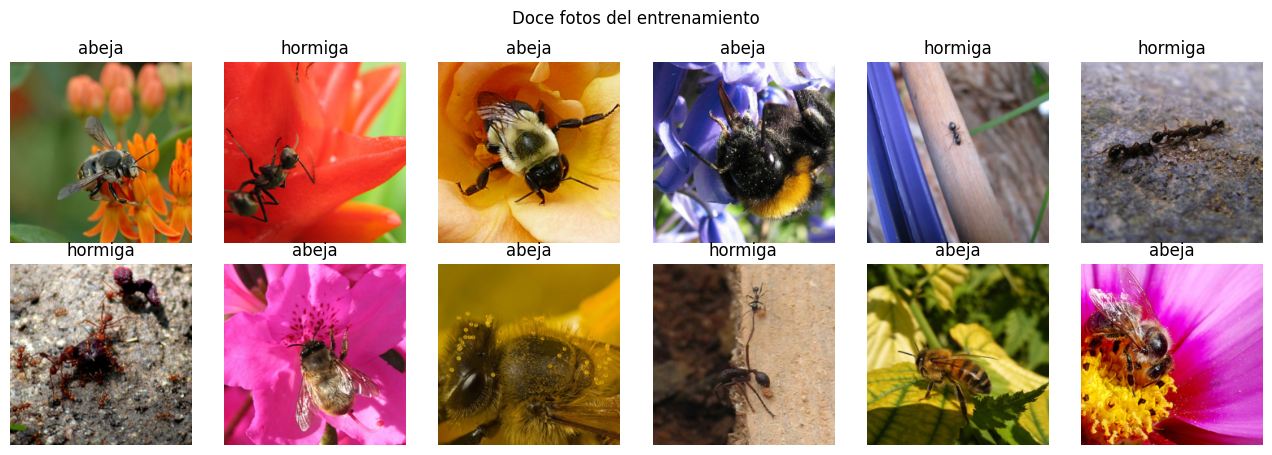

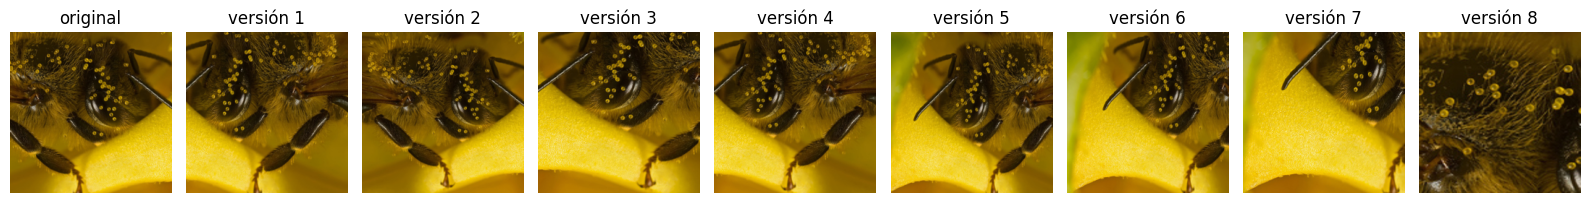

In [7]:
# Abre una foto del disco y le aplica el mismo recorte central que la evaluación, sin normalizar
def abrir_centrada(ruta):
    # Abrimos la foto en color
    img = Image.open(ruta).convert("RGB")
    # Resize(256) + CenterCrop(224), igual que tf_eval pero sin pasar a tensor
    return transforms.CenterCrop(224)(transforms.Resize(256)(img))

# Fijamos la semilla para que todos veamos las mismas doce fotos
fijar_semilla(P["SEMILLA"])
# Elegimos doce índices al azar del entrenamiento
idx_gal = random.sample(range(len(ds_train)), 12)

# Una figura de 2 filas por 6 columnas
fig, axes = plt.subplots(2, 6, figsize=(13, 4.6))
# Recorremos los doce recuadros a la vez que los índices
for ax, i in zip(axes.flat, idx_gal):
    # samples guarda (ruta, etiqueta) de cada foto
    ruta, y = ds_train.samples[i]
    # Mostramos la foto recortada al centro
    ax.imshow(abrir_centrada(ruta))
    # Título con la clase
    ax.set_title(CLASES[y])
    # Sin ejes numéricos
    ax.axis("off")
# Título general
plt.suptitle("Doce fotos del entrenamiento")
# Ajuste de márgenes
plt.tight_layout()
# Mostramos
plt.show()

# Buscamos la primera abeja del entrenamiento
ruta_abeja = next(r for r, y in ds_train.samples if y == 1)
# La abrimos tal cual viene del disco
foto = Image.open(ruta_abeja).convert("RGB")
# La receta de aumento, pero sin pasar a tensor, para poder verla como foto
aumento_vis = transforms.Compose([transforms.RandomResizedCrop(224), transforms.RandomHorizontalFlip()])

# Una fila de 9 recuadros: la original y ocho versiones
fig, axes = plt.subplots(1, 9, figsize=(16, 2.4))
# La original, con el recorte central
axes[0].imshow(abrir_centrada(ruta_abeja))
# Su título
axes[0].set_title("original")
# Recorremos los otros ocho recuadros
for k, ax in enumerate(axes[1:]):
    # Cada vez que llamamos a aumento_vis sale una versión distinta
    ax.imshow(aumento_vis(foto))
    # Título con el número de versión
    ax.set_title(f"versión {k + 1}")
# Quitamos los ejes de todos
for ax in axes:
    # Sin números en los bordes
    ax.axis("off")
# Ajuste y mostrar
plt.tight_layout()
# Mostramos
plt.show()

**Cómo leerlo.** Mira cuánto varían las fotos. Hay hormigas enormes que llenan el cuadro y otras que son un punto sobre una flor, abejas de espaldas y abejas borrosas. Las ocho versiones de la misma abeja muestran a veces solo el ala, a veces el cuerpo entero, a veces en espejo. Para nosotros es obvio que todas son la misma abeja porque ya sabemos ver, y eso es justamente lo que una red nueva no sabe todavía.

---
## Parte 4 — El motor de entrenamiento

Es el mismo motor de la Clase 7 con dos cambios. El primero es que el optimizador recibe **solo los parámetros que siguen activos** (`requires_grad=True`), porque en transfer learning muchos van a estar congelados. El segundo es que al terminar nos quedamos con los pesos de la época que tuvo **mejor exactitud en validación**, como hacía el early stopping, para que ningún modelo salga perjudicado por sus últimas épocas.

También definimos `run`, una función que hace todo el experimento de una vez (crea el modelo, lo entrena, lo mide en prueba y guarda los resultados), y `ver_curvas`, que dibuja las curvas de entrenamiento y validación.

In [8]:
# Mide pérdida y exactitud de un modelo sobre un cargador, sin entrenar
def evaluar(model, loader):
    # Modo evaluación: apaga el dropout y congela las estadísticas de BatchNorm
    model.eval()
    # Función de pérdida para clasificación
    crit = nn.CrossEntropyLoss()
    # Contadores: fotos vistas, aciertos y suma de pérdidas
    total, correctos, perdida = 0, 0, 0.0
    # no_grad: no guardamos gradientes, porque aquí no se aprende
    with torch.no_grad():
        # Recorremos los lotes
        for X, y in loader:
            # Mandamos fotos y etiquetas a la GPU
            X, y = X.to(device), y.to(device)
            # La red produce una puntuación por clase
            logits = model(X)
            # Sumamos la pérdida del lote, ponderada por su tamaño
            perdida += crit(logits, y).item() * len(y)
            # Contamos aciertos: la clase con mayor puntuación contra la real
            correctos += (logits.argmax(1) == y).sum().item()
            # Sumamos las fotos del lote
            total += len(y)
    # Devolvemos pérdida promedio y exactitud
    return perdida / total, correctos / total


# Devuelve las probabilidades por clase de cada foto, en el orden del cargador
def predecir(model, loader):
    # Modo evaluación
    model.eval()
    # Aquí juntamos las probabilidades y las etiquetas reales
    probs, ys = [], []
    # Sin gradientes
    with torch.no_grad():
        # Recorremos los lotes
        for X, y in loader:
            # softmax convierte las puntuaciones en probabilidades que suman 1
            probs.append(torch.softmax(model(X.to(device)), 1).cpu())
            # Guardamos las etiquetas reales
            ys.append(y)
    # Unimos todos los lotes en una sola matriz y un solo vector
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()


# Cuenta parámetros: los que se entrenan y el total
def contar(model):
    # Suma los parámetros con requires_grad=True (los que el optimizador moverá)
    entrenables = sum(p.numel() for p in model.parameters() if p.requires_grad)
    # Suma todos
    totales = sum(p.numel() for p in model.parameters())
    # Devolvemos los dos
    return entrenables, totales


# Entrena un modelo y registra las cuatro curvas de la Clase 7
def entrenar(model, loader, epocas, lr, wd=0.0):
    # Llevamos el modelo a la GPU
    model = model.to(device)
    # Solo los parámetros activos; los congelados quedan fuera del optimizador
    activos = [p for p in model.parameters() if p.requires_grad]
    # Adam, el optimizador de la Clase 7, con su tasa de aprendizaje y su weight decay
    opt = torch.optim.Adam(activos, lr=lr, weight_decay=wd)
    # Pérdida de clasificación
    crit = nn.CrossEntropyLoss()
    # Historial de las cuatro curvas
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    # Mejor exactitud en validación vista hasta ahora, su época y una copia de esos pesos
    mejor_va, mejor_ep, mejor_estado = -1.0, 0, None
    # Arrancamos el cronómetro
    t0 = time.time()
    # Recorremos las épocas
    for ep in range(1, epocas + 1):
        # Modo entrenamiento
        model.train()
        # Contadores de la época
        total, correctos, perdida = 0, 0, 0.0
        # Recorremos los lotes del entrenamiento
        for X, y in loader:
            # A la GPU
            X, y = X.to(device), y.to(device)
            # Borramos los gradientes del paso anterior
            opt.zero_grad()
            # Predicción del lote
            logits = model(X)
            # Pérdida del lote
            loss = crit(logits, y)
            # Calculamos gradientes (solo llegan a los parámetros activos)
            loss.backward()
            # Movemos los pesos activos
            opt.step()
            # Acumulamos la pérdida del lote para la curva de entrenamiento
            perdida += loss.item() * len(y)
            # Acumulamos los aciertos del lote
            correctos += (logits.argmax(1) == y).sum().item()
            # Acumulamos las fotos del lote
            total += len(y)
        # Medimos en validación al final de la época
        vl, va = evaluar(model, val_loader)
        # Guardamos la pérdida de entrenamiento de la época
        hist["train_loss"].append(perdida / total)
        # La exactitud de entrenamiento
        hist["train_acc"].append(correctos / total)
        # La pérdida de validación
        hist["val_loss"].append(vl)
        # La exactitud de validación
        hist["val_acc"].append(va)
        # Si esta época superó a la mejor, la recordamos
        if va > mejor_va:
            # Nueva mejor exactitud, su época y una copia independiente de los pesos
            mejor_va, mejor_ep, mejor_estado = va, ep, copy.deepcopy(model.state_dict())
    # Volvemos a los pesos de la mejor época
    model.load_state_dict(mejor_estado)
    # Devolvemos el modelo, su historial, la mejor época y los segundos que tardó
    return model, hist, mejor_ep, time.time() - t0


# Aquí guardamos los resultados de cada experimento
RES = {}
# Y aquí los modelos ya entrenados
MOD = {}

# Corre un experimento completo: crea el modelo, lo entrena, lo mide en prueba y guarda todo
def run(nombre, crear_modelo, ds, epocas, lr, wd=0.0):
    # Misma semilla antes de crear el modelo: todos arrancan igual de justos
    fijar_semilla(P["SEMILLA"])
    # Construimos el modelo con la función que nos pasan
    model = crear_modelo()
    # Contamos sus parámetros antes de entrenar
    entrenables, totales = contar(model)
    # Entrenamos
    model, hist, mejor_ep, seg = entrenar(model, loader_train(ds), epocas, lr, wd)
    # Medimos en prueba, una sola vez
    tl, ta = evaluar(model, test_loader)
    # Probabilidades de cada foto de prueba (para la matriz y para mirar errores)
    probs, ys = predecir(model, test_loader)
    # Guardamos todo lo que vamos a necesitar después
    RES[nombre] = {"hist": hist, "test_acc": ta, "test_loss": tl, "probs": probs, "ys": ys,
                   "mejor_ep": mejor_ep, "entrenables": entrenables, "totales": totales, "seg": seg}
    # Guardamos el modelo entrenado
    MOD[nombre] = model
    # Resumen en una línea
    print(f"{nombre}: {entrenables:,} parámetros entrenables | mejor época {mejor_ep} | "
          f"validación {hist['val_acc'][mejor_ep - 1]:.3f} | prueba {ta:.3f} | {seg:.0f} s")


# Dibuja las curvas de exactitud (o de pérdida) de uno o varios experimentos
def ver_curvas(nombres, titulo, medida="acc"):
    # Una figura con dos paneles: entrenamiento y validación
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    # Recorremos los experimentos
    for n in nombres:
        # Historial del experimento
        h = RES[n]["hist"]
        # Eje x: número de época
        ep = range(1, len(h["val_" + medida]) + 1)
        # Entrenamiento en el panel izquierdo
        ax[0].plot(ep, h["train_" + medida], label=n)
        # Validación en el panel derecho
        ax[1].plot(ep, h["val_" + medida], label=n)
    # Nombre de la medida para los títulos
    nombre_medida = "Exactitud" if medida == "acc" else "Pérdida"
    # Título del panel izquierdo
    ax[0].set_title(nombre_medida + " en entrenamiento")
    # Título del panel derecho
    ax[1].set_title(nombre_medida + " en validación")
    # Recorremos los dos paneles para ponerles leyenda y eje x
    for a in ax:
        # Leyenda
        a.legend()
        # Eje x
        a.set_xlabel("época")
        # La exactitud va de 0 a 1
        if medida == "acc":
            # Límites del eje y
            a.set_ylim(0, 1.02)
    # Título general
    fig.suptitle(titulo)
    # Ajuste de márgenes
    plt.tight_layout()
    # Mostramos
    plt.show()

# Confirmamos que el motor está listo
print("Motor listo: evaluar, predecir, contar, entrenar, run y ver_curvas.")

Motor listo: evaluar, predecir, contar, entrenar, run y ver_curvas.


**Una pregunta antes de seguir.** Si el optimizador solo recibe los parámetros activos, ¿qué les pasa a los congelados cuando se llama a `opt.step()`? Nada, porque el optimizador ni siquiera sabe que existen, y además `loss.backward()` no les calcula gradiente. Lo vamos a comprobar con una red de juguete en la Parte 7.

---
## Parte 5 — La línea base desde cero

Antes de traer al gigante repetimos la vía difícil de la Clase 7, una CNN pequeña que empieza con pesos al azar y tiene que aprender a ver y a distinguir abejas de hormigas solo con las 244 fotos. Tiene cuerpo y cabeza separados, igual que las redes de la Clase 6, y su exactitud en prueba es **el número a vencer**.

Esta celda tarda alrededor de un minuto con GPU, porque son 30 épocas.

cero: 389,890 parámetros entrenables | mejor época 21 | validación 0.789 | prueba 0.805 | 60 s


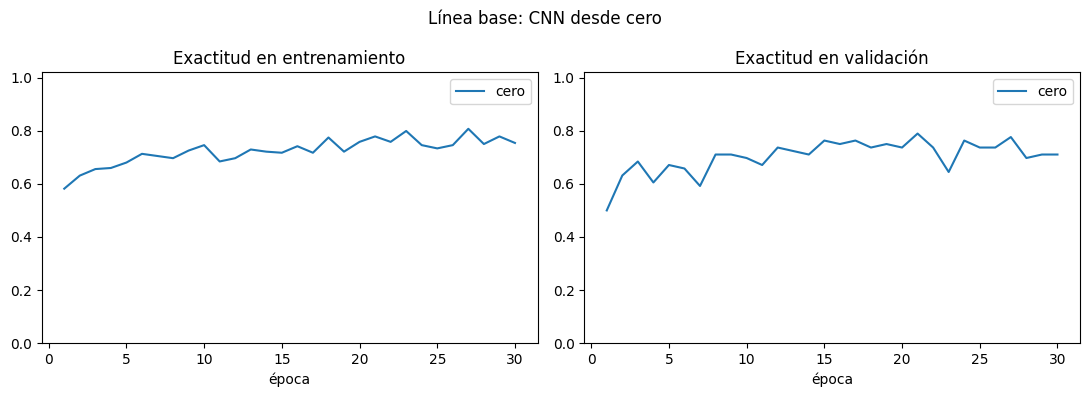

In [9]:
# CNN pequeña escrita a mano, con cuerpo y cabeza separados
class CNNDesdeCero(nn.Module):
    # Aquí se declaran las capas
    def __init__(self, n_clases=2):
        # Inicializa la parte interna de nn.Module
        super().__init__()
        # El cuerpo: cuatro bloques convolucionales que reducen la foto a la mitad cada vez
        self.cuerpo = nn.Sequential(
            # Bloque 1: 3 canales de color → 32 mapas; 224 → 112 tras el pooling
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            # Bloque 2: 32 → 64 mapas; 112 → 56
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            # Bloque 3: 64 → 128 mapas; 56 → 28
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
            # Bloque 4: 128 → 256 mapas; 28 → 14
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(), nn.MaxPool2d(2),
            # Promedia cada mapa de 14 x 14 en un solo número: quedan 256 números por foto
            nn.AdaptiveAvgPool2d(1),
        )
        # La cabeza: aplana, apaga el 30 % al azar (dropout de la Clase 7) y decide entre 2 clases
        self.cabeza = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, n_clases))

    # Camino que recorre una foto dentro de la red
    def forward(self, x):
        # Primero el cuerpo y luego la cabeza
        return self.cabeza(self.cuerpo(x))

# Entrenamos la línea base con la tasa habitual y 30 épocas
run("cero", lambda: CNNDesdeCero(), ds_train, P["EP_CERO"], P["LR_BASE"])
# Dibujamos sus curvas
ver_curvas(["cero"], "Línea base: CNN desde cero")

**Cómo leerlo.** En la corrida del docente la red desde cero llegó a **80,5 % en prueba**, es decir falló 15 de las 77 fotos, y su mejor época fue la 21. Mira las curvas, suben despacio y la de validación sube y baja mucho de una época a otra (entre 50 % y 79 %), porque con tan pocas fotos cada época la red cambia de opinión sobre bastantes de ellas. Tiene 389 890 parámetros y los entrenó todos desde el azar. Ese 80,5 % es el número a vencer.

---
## Parte 6 — Conocer al gigante

ResNet-18 es una red de 18 capas que se entrenó con **ImageNet**, un conjunto de 1,2 millones de fotos repartidas en 1000 clases (animales, objetos, vehículos, comida). Ese entrenamiento lo hicieron otros, con mucho cómputo, y PyTorch nos regala el resultado, los pesos, que se descargan la primera vez (unos 45 MB).

Vamos a mirarla por dentro, bloque por bloque, contando los parámetros de cada parte. La pieza que más nos importa es la última, `fc`, que es la **cabeza** y decide entre las 1000 clases de ImageNet. Todo lo anterior es el **cuerpo**, lo que aprendió a ver.

In [10]:
# Pesos oficiales de ResNet-18 entrenada en ImageNet (1,2 millones de fotos, 1000 clases)
PESOS = models.ResNet18_Weights.IMAGENET1K_V1
# Cargamos la red con esos pesos (la primera vez los descarga)
resnet = models.resnet18(weights=PESOS)
# La misma arquitectura sin pesos aprendidos, solo con números al azar, para comparar
resnet_azar = models.resnet18(weights=None)

# Total de parámetros, lo vamos sumando bloque por bloque
total = 0
# named_children recorre los bloques de primer nivel de la red, en orden
for nombre, modulo in resnet.named_children():
    # Parámetros del bloque
    n = sum(p.numel() for p in modulo.parameters())
    # Lo sumamos al total
    total += n
    # Lo mostramos en una tabla sencilla
    print(f"{nombre:>8}: {n:>10,} parámetros")
# Mostramos el total
print(f"{'TOTAL':>8}: {total:>10,}")

# La cabeza original: recibe 512 números y saca 1000 clases de ImageNet
print("\nCabeza original:", resnet.fc)
# in_features es el tamaño del vector que produce el cuerpo
print("El cuerpo entrega", resnet.fc.in_features, "números por foto.")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 147MB/s]


   conv1:      9,408 parámetros
     bn1:        128 parámetros
    relu:          0 parámetros
 maxpool:          0 parámetros
  layer1:    147,968 parámetros
  layer2:    525,568 parámetros
  layer3:  2,099,712 parámetros
  layer4:  8,393,728 parámetros
 avgpool:          0 parámetros
      fc:    513,000 parámetros
   TOTAL: 11,689,512

Cabeza original: Linear(in_features=512, out_features=1000, bias=True)
El cuerpo entrega 512 números por foto.


**Cómo leerlo.** Son 11 689 512 parámetros en total. Fíjate en dos cosas. La primera es que `layer4`, el último bloque del cuerpo, tiene 8 393 728, más del 70 % de toda la red, porque trabaja con 512 mapas de características. La segunda es que la cabeza `fc` tiene 513 000, que salen de 512 entradas por 1000 salidas más 1000 sesgos, y que esa cabeza no nos sirve porque nosotros no tenemos 1000 clases sino dos. El cuerpo entrega 512 números por foto, y ese 512 es el que tendrá que recibir nuestra cabeza nueva.

Ahora veamos con los ojos lo que aprendió el cuerpo. La primera capa, `conv1`, tiene 64 filtros de 7 × 7 píxeles en color. Los dibujamos todos, los de la red preentrenada y los de la red al azar.

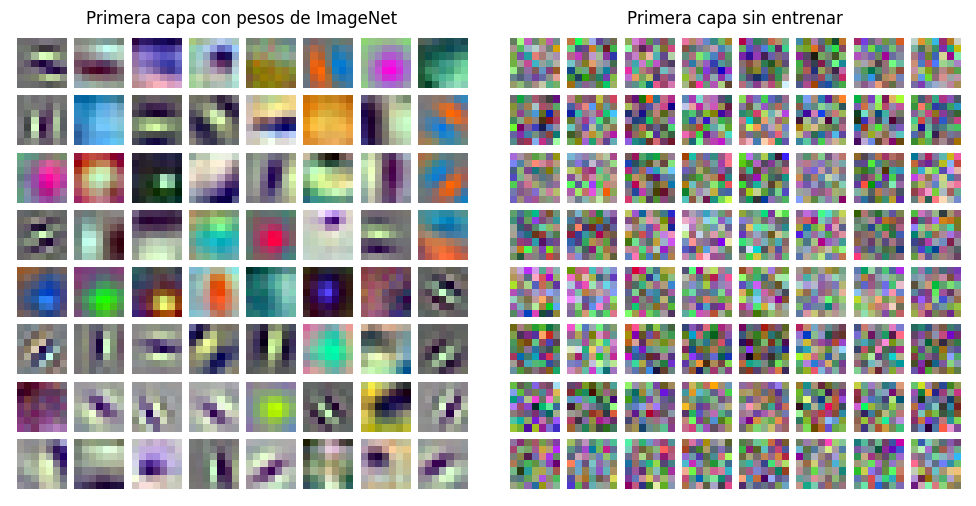

In [11]:
# Convierte los 64 filtros de la primera capa en una sola imagen de 8 x 8 filtros
def mosaico_filtros(conv):
    # Pesos de la capa: forma [64 filtros, 3 colores, 7, 7]
    w = conv.weight.detach().cpu().clone()
    # Lienzo blanco de 8 x 8 filtros de 7 píxeles, con 1 píxel de separación
    lienzo = np.ones((8 * 8 + 1, 8 * 8 + 1, 3))
    # Recorremos los 64 filtros
    for i in range(64):
        # Filtro i, reordenado a [7, 7, 3] para verlo como imagen de color
        f = w[i].permute(1, 2, 0).numpy()
        # Estiramos sus valores entre 0 y 1 para que se vean
        f = (f - f.min()) / (f.max() - f.min() + 1e-8)
        # Fila y columna del filtro dentro del mosaico
        fila, col = divmod(i, 8)
        # Lo pegamos en su lugar
        lienzo[1 + fila * 8: 1 + fila * 8 + 7, 1 + col * 8: 1 + col * 8 + 7] = f
    # Devolvemos el mosaico
    return lienzo

# Dos paneles lado a lado
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
# Izquierda: lo que aprendió ImageNet
ax[0].imshow(mosaico_filtros(resnet.conv1), interpolation="nearest")
# Título del panel izquierdo
ax[0].set_title("Primera capa con pesos de ImageNet")
# Derecha: la misma capa sin entrenar
ax[1].imshow(mosaico_filtros(resnet_azar.conv1), interpolation="nearest")
# Título del panel derecho
ax[1].set_title("Primera capa sin entrenar")
# Quitamos los ejes de los dos paneles
for a in ax:
    # Sin números en los bordes
    a.axis("off")
# Ajuste y mostrar
plt.tight_layout()
# Mostramos
plt.show()

**Cómo leerlo.** A la izquierda aparecen rayas inclinadas en varias direcciones, manchas de color y pequeños círculos, que son detectores de bordes, de cambios de color y de texturas, muy parecidos a los filtros que diseñamos a mano en la Unidad 1. Nadie los programó, la red los descubrió sola viendo 1,2 millones de fotos. A la derecha solo hay puntos de colores sueltos, sin ninguna dirección ni forma. Esa es la diferencia entre saber leer y no saber, las letras ya están ahí en la red preentrenada, y en la red al azar todavía no.

---
## Parte 7 — Primero lo pequeño: congelar

Antes de congelar 11 millones de parámetros, congelemos unos pocos. Armamos una red de juguete con dos capas, un "cuerpo" de 2 a 2 y una "cabeza" de 2 a 1, congelamos el cuerpo con `requires_grad = False`, damos un solo paso de entrenamiento y comparamos los pesos antes y después.

In [12]:
# Semilla para que el ejemplo dé siempre los mismos números
fijar_semilla(P["SEMILLA"])
# Red de juguete: una capa de 2 a 2 (el "cuerpo") y otra de 2 a 1 (la "cabeza")
juguete = nn.Sequential(nn.Linear(2, 2), nn.Linear(2, 1))

# Recorremos los parámetros de la primera capa
for p in juguete[0].parameters():
    # requires_grad=False es el interruptor de congelar
    p.requires_grad = False

# Copia de los pesos del cuerpo ANTES de entrenar
antes_cuerpo = juguete[0].weight.detach().clone()
# Copia de los pesos de la cabeza ANTES de entrenar
antes_cabeza = juguete[1].weight.detach().clone()

# Optimizador solo con los parámetros activos (los de la cabeza)
opt = torch.optim.SGD([p for p in juguete.parameters() if p.requires_grad], lr=0.5)
# Un dato de entrada inventado
x = torch.tensor([[1.0, 2.0]])
# Su valor objetivo inventado
y = torch.tensor([[3.0]])
# Error cuadrático entre la predicción y el objetivo
loss = ((juguete(x) - y) ** 2).mean()
# Calculamos gradientes
loss.backward()
# Damos UN paso de entrenamiento
opt.step()

# Cuerpo antes del paso
print("Cuerpo (congelado)  antes:", antes_cuerpo.numpy().round(3).tolist())
# Cuerpo después del paso: debe ser idéntico
print("                  después:", juguete[0].weight.detach().numpy().round(3).tolist())
# Cabeza antes del paso
print("Cabeza (activa)     antes:", antes_cabeza.numpy().round(3).tolist())
# Cabeza después del paso: debe haber cambiado
print("                  después:", juguete[1].weight.detach().numpy().round(3).tolist())
# El gradiente del cuerpo ni siquiera se calculó
print("Gradiente del cuerpo:", juguete[0].weight.grad)

Cuerpo (congelado)  antes: [[-0.004999999888241291, 0.3790000081062317], [-0.5820000171661377, -0.5199999809265137]]
                  después: [[-0.004999999888241291, 0.3790000081062317], [-0.5820000171661377, -0.5199999809265137]]
Cabeza (activa)     antes: [[-0.014000000432133675, 0.5609999895095825]]
                  después: [[1.8489999771118164, -4.989999771118164]]
Gradiente del cuerpo: None


**Cómo leerlo.** Los pesos del cuerpo salen idénticos antes y después, ni un decimal distinto, y su gradiente es `None`, es decir que PyTorch ni siquiera lo calculó. La cabeza, en cambio, se movió bastante (en la corrida del docente pasó de `[-0.014, 0.561]` a `[1.849, -4.99]`). Eso es congelar, la parte congelada conserva lo que sabía y solo aprende la parte activa. Con ResNet-18 vamos a hacer exactamente lo mismo, solo que el cuerpo tendrá 11 millones de parámetros en lugar de seis.

---
## Parte 8 — Estrategia 1: feature extraction

La primera estrategia se llama *feature extraction*, extracción de características, y tiene dos pasos. Congelamos **todo** el cuerpo de ResNet-18, y reemplazamos la cabeza de 1000 clases por una nueva de 2. Una capa recién creada nace activa, así que lo único que aprende es la cabeza nueva. El cuerpo se vuelve un lector fijo que convierte cada foto en 512 números, y la cabeza aprende a leer en esos 512 números si hay una abeja o una hormiga.

Escribimos una sola función, `crear_resnet`, que nos servirá para todas las variantes del resto del notebook, porque cambia dos decisiones, si parte con los pesos de ImageNet o al azar, y qué partes quedan activas.

fe: 1,026 parámetros entrenables | mejor época 3 | validación 0.934 | prueba 0.935 | 29 s


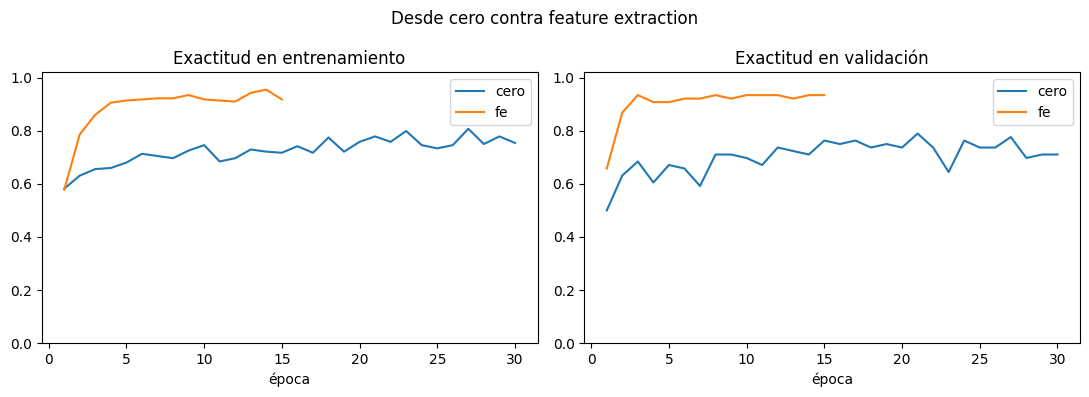

In [13]:
# Arma una ResNet-18 para 2 clases según dos decisiones
def crear_resnet(preentrenada=True, activas="cabeza"):
    # Con pesos de ImageNet o sin ellos
    m = models.resnet18(weights=PESOS if preentrenada else None)
    # Si solo debe aprender la cabeza, o layer4 y la cabeza, primero congelamos todo
    if activas in ("cabeza", "layer4", "layer3"):
        # Recorremos todos los parámetros
        for p in m.parameters():
            # Y los congelamos
            p.requires_grad = False
    # Si además debe aprender layer4 (o layer3 y layer4), lo reactivamos
    if activas in ("layer4", "layer3"):
        # Recorremos los parámetros de layer4
        for p in m.layer4.parameters():
            # Y los descongelamos
            p.requires_grad = True
    # Si también debe aprender layer3, lo reactivamos (lo usarás en el TU TURNO)
    if activas == "layer3":
        # Recorremos los parámetros de layer3
        for p in m.layer3.parameters():
            # Y los descongelamos
            p.requires_grad = True
    # Cabeza nueva: 512 números de entrada, 2 clases de salida (una capa nueva nace activa)
    m.fc = nn.Linear(m.fc.in_features, len(CLASES))
    # Devolvemos la red lista
    return m

# Estrategia 1: cuerpo preentrenado congelado, solo la cabeza aprende
run("fe", lambda: crear_resnet(True, "cabeza"), ds_train, P["EP_TL"], P["LR_BASE"])
# Comparamos sus curvas con las de la red desde cero
ver_curvas(["cero", "fe"], "Desde cero contra feature extraction")

**Cómo leerlo.** El número de parámetros entrenables es **1 026**, que salen de 512 × 2 pesos más 2 sesgos, apenas el 0,009 % de los 11 177 538 que tiene la red con su cabeza nueva. Aun así, en la corrida del docente llegó a **93,5 % en prueba** (5 errores de 77) contra 80,5 % de la red desde cero (15 errores), en la mitad del tiempo y con la mitad de épocas.

Mira también que la curva de validación salta a más de 90 % en la tercera época, mientras la red desde cero sigue tanteando. La cabeza no tuvo que aprender a ver, solo a nombrar.

Puede que te llame la atención que la exactitud de entrenamiento salga **más baja** que la de validación (en la corrida del docente, 86 % contra 93 % en la mejor época). No es un error, la de entrenamiento se mide sobre fotos recortadas al azar, muchas veces sin el insecto completo, y mientras la red todavía está aprendiendo en esa época, en cambio la de validación se mide al final de la época y con fotos limpias, centradas.

---
## Parte 9 — Estrategia 2: fine-tuning

La segunda estrategia va un paso más allá. Además de la cabeza nueva, **descongelamos el último bloque del cuerpo**, `layer4`, para que se ajuste a abejas y hormigas. La regla práctica es que las capas tempranas aprendieron cosas generales (bordes, colores, texturas) que sirven para cualquier foto, y las tardías aprendieron cosas más específicas de ImageNet, así que esas son las que vale la pena ajustar.

El detalle crítico es la tasa de aprendizaje, que bajamos diez veces, de 0,001 a **0,0001**. El cuerpo ya sabe mucho, y queremos corregirlo con pasos pequeños, como quien pule un texto bien escrito en vez de reescribirlo. Le sumamos el weight decay de la Clase 7 porque ahora hay muchos más parámetros libres.

ft: 8,394,754 parámetros entrenables | mejor época 1 | validación 0.947 | prueba 0.896 | 27 s


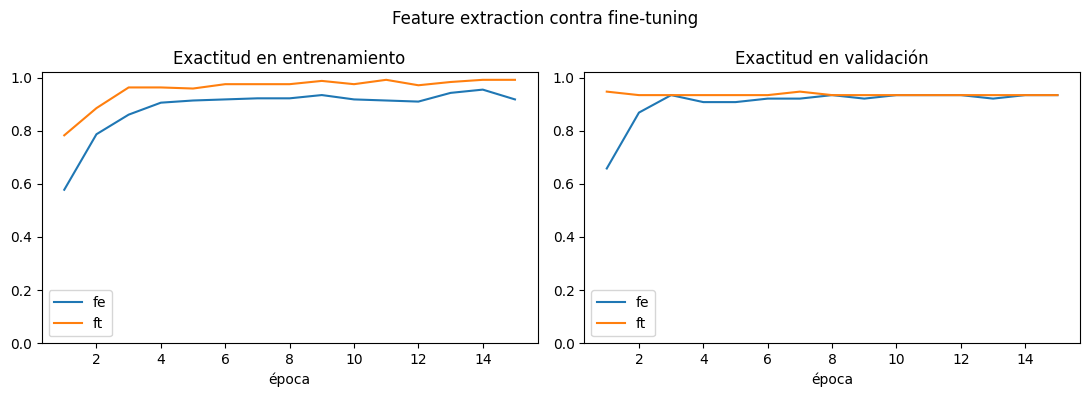

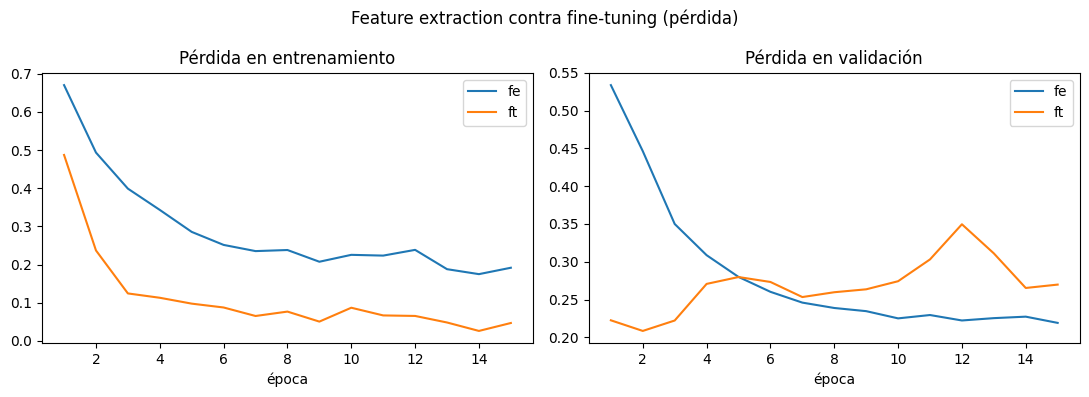

In [14]:
# Estrategia 2: layer4 y cabeza activos, tasa de aprendizaje diez veces menor y weight decay
run("ft", lambda: crear_resnet(True, "layer4"), ds_train, P["EP_TL"], P["LR_FT"], wd=P["WD"])
# Curvas de exactitud de las dos estrategias
ver_curvas(["fe", "ft"], "Feature extraction contra fine-tuning")
# Curvas de pérdida, donde se ve mejor la memorización
ver_curvas(["fe", "ft"], "Feature extraction contra fine-tuning (pérdida)", medida="loss")

**Cómo leerlo.** Ahora se entrenan **8 394 754** parámetros, los 8 393 728 de `layer4` más los 1 026 de la cabeza, alrededor del 75 % de la red. En la corrida del docente el fine-tuning llegó a **89,6 % en prueba** (8 errores), prácticamente empatado con feature extraction (5 errores), porque con 77 fotos de prueba tres fotos de diferencia son ruido.

Lo interesante está en las curvas. Su mejor época fue la **primera**, y desde ahí la exactitud de entrenamiento sube hasta 99 % mientras la pérdida de validación **sube** de 0,21 a 0,35. Es el síntoma de la Clase 7, la red está memorizando. Con 244 fotos, dejarle 8 millones de parámetros libres le da memoria de sobra para aprenderse las fotos de entrenamiento, y no gana nada frente a congelar. El fine-tuning paga cuando hay más datos, no con un folleto de 244 fotos.

---
## Parte 10 — El error clásico: tasa de aprendizaje alta

Repetimos el fine-tuning exactamente igual, con una sola diferencia, la tasa de aprendizaje es **0,01**, cien veces mayor que la del fine-tuning sano. Es el error más común cuando alguien hace transfer learning por primera vez, porque copia la tasa de un entrenamiento desde cero sin pensar que el cuerpo ya sabe mucho.

Antes de ejecutar, apuesta en una línea, ¿qué crees que le pasará a la pérdida de validación en la primera época?

lr_alto: 8,394,754 parámetros entrenables | mejor época 4 | validación 0.947 | prueba 0.883 | 28 s
ft pérdida de validación, épocas 1 a 5: [0.22, 0.21, 0.22, 0.27, 0.28]
lr_alto pérdida de validación, épocas 1 a 5: [30.0, 5.79, 2.24, 1.25, 0.89]


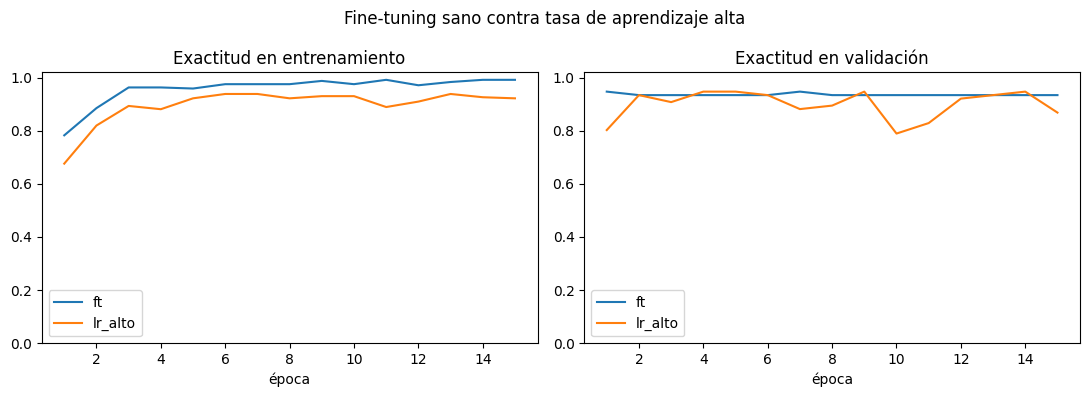

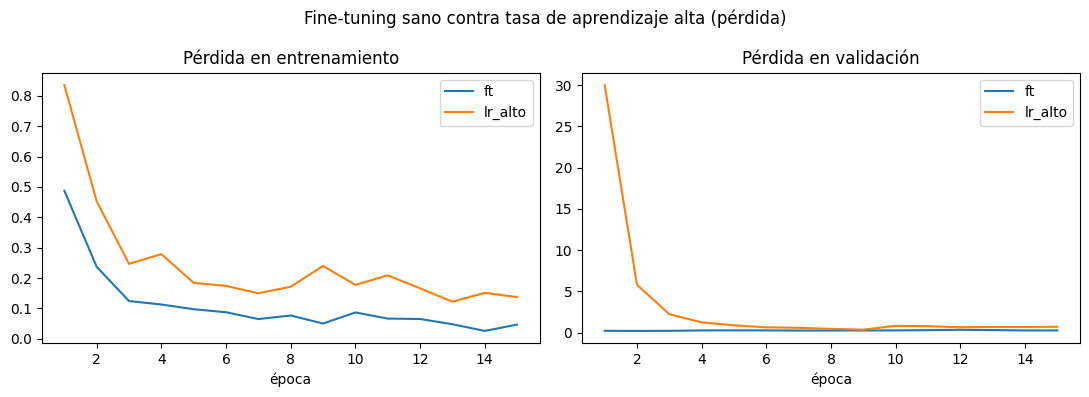

In [15]:
# El mismo fine-tuning, pero con tasa de aprendizaje 0,01 (cien veces mayor)
run("lr_alto", lambda: crear_resnet(True, "layer4"), ds_train, P["EP_TL"], P["LR_ALTO"], wd=P["WD"])
# Pérdida de validación de las primeras cinco épocas, del sano y del enfermo
for n in ["ft", "lr_alto"]:
    # Redondeamos para leerlas fácil
    print(n, "pérdida de validación, épocas 1 a 5:", [round(v, 2) for v in RES[n]["hist"]["val_loss"][:5]])
# Curvas de exactitud comparadas
ver_curvas(["ft", "lr_alto"], "Fine-tuning sano contra tasa de aprendizaje alta")
# Curvas de pérdida comparadas
ver_curvas(["ft", "lr_alto"], "Fine-tuning sano contra tasa de aprendizaje alta (pérdida)", medida="loss")

**Cómo leerlo.** En la corrida del docente, la pérdida de validación del modelo sano en la primera época fue 0,22 y la del modelo con tasa alta fue **30,0**, más de cien veces peor. En un solo paso de época, los pasos gigantes desordenaron los pesos de `layer4` que ImageNet había afinado durante días de cómputo. Después se recupera en parte, porque las capas tempranas siguen congeladas y conservan las "letras", pero la curva de validación queda errática, saltando entre 79 % y 95 %.

Llegó a 88,3 % en prueba, cerca de los otros, porque el motor se queda con la mejor época. Pero mira la pérdida en prueba, que en la corrida del docente fue 0,63 contra 0,215 del sano, casi el triple. Eso significa que cuando se equivoca lo hace muy seguro, tuvo 5 errores con más del 90 % de seguridad, mientras los demás modelos tuvieron uno o ninguno. Un modelo que se equivoca con aplomo es peligroso en la práctica, y lo veremos foto por foto en la Parte 12.

---
## Parte 11 — El veredicto y la matriz de confusión

Ahora juntamos todo frente al juez, las 77 fotos de prueba que ningún modelo vio ni usamos para decidir.

 experimento | entrenables | mejor ép. |  prueba | errores
------------------------------------------------------------
        cero |     389,890 |        21 |   0.805 |   15 / 77
          fe |       1,026 |         3 |   0.935 |    5 / 77
          ft |   8,394,754 |         1 |   0.896 |    8 / 77
     lr_alto |   8,394,754 |         4 |   0.883 |    9 / 77


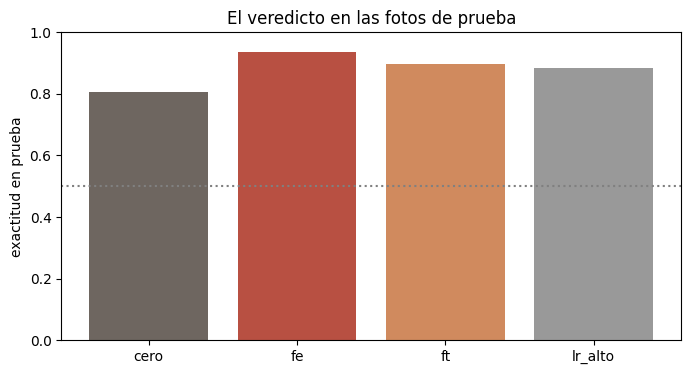

In [16]:
# Orden en que mostramos los experimentos
ORDEN = ["cero", "fe", "ft", "lr_alto"]
# Encabezado de la tabla
print(f"{'experimento':>12} | {'entrenables':>11} | {'mejor ép.':>9} | {'prueba':>7} | {'errores':>7}")
# Línea separadora
print("-" * 60)
# Una fila por experimento
for n in ORDEN:
    # Resultado del experimento
    r = RES[n]
    # Errores en prueba: fotos donde la clase predicha no es la real
    errores = int((r["probs"].argmax(1) != r["ys"]).sum())
    # Fila con las cifras principales
    print(f"{n:>12} | {r['entrenables']:>11,} | {r['mejor_ep']:>9} | {r['test_acc']:>7.3f} | {errores:>4} / {len(r['ys'])}")

# Barras con la exactitud en prueba de cada experimento
plt.figure(figsize=(8, 4))
# Colores de la clase: gris pardo para desde cero, terracota para feature extraction, tonos tierra para los demás
plt.bar(ORDEN, [RES[n]["test_acc"] for n in ORDEN], color=["#6E6660", "#B85042", "#D08A5E", "#999999"])
# Línea del azar (50 % con dos clases)
plt.axhline(0.5, ls=":", c="gray")
# Eje y de 0 a 1
plt.ylim(0, 1)
# Nombre del eje y
plt.ylabel("exactitud en prueba")
# Título
plt.title("El veredicto en las fotos de prueba")
# Mostramos
plt.show()

**Cómo leerlo.** El salto grande está entre la primera barra y las demás, de unos 80 % a unos 90 %, y ese salto es lo que se gana partiendo de un cuerpo que ya sabe ver. Entre las tres barras de transfer learning las diferencias son de pocas fotos, así que no conviene declarar un ganador por un punto. Lo que sí distingue a las estrategias son las curvas, feature extraction aprendió estable y sin memorizar, el fine-tuning memorizó desde la segunda época, y la tasa alta se volvió errática.

La exactitud es un solo número. La matriz de confusión nos dice **dónde** se equivoca cada modelo, como en la Clase 7.

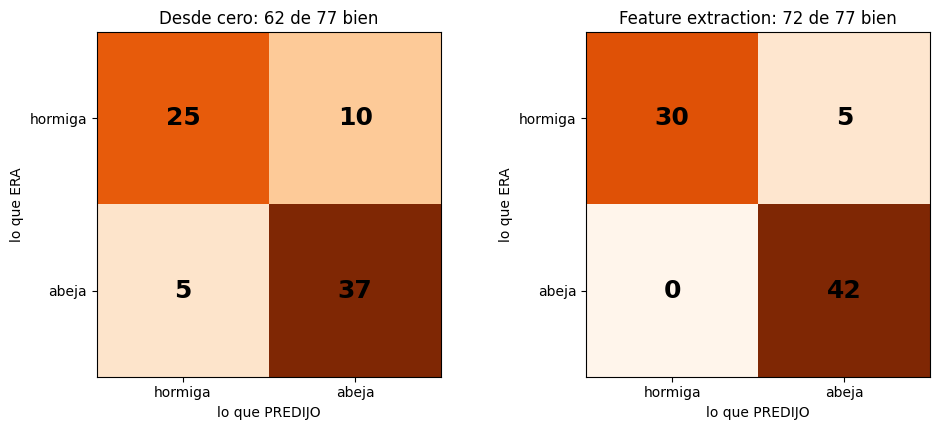

In [17]:
# Dibuja la matriz de confusión de un experimento en un panel
def dibujar_matriz(ax, nombre, titulo):
    # Filas = clase real, columnas = clase predicha
    cm = confusion_matrix(RES[nombre]["ys"], RES[nombre]["probs"].argmax(1), labels=[0, 1])
    # Pintamos la matriz con tonos naranjas
    ax.imshow(cm, cmap="Oranges", vmin=0)
    # Recorremos las filas
    for i in range(2):
        # Recorremos las columnas
        for j in range(2):
            # Escribimos el número en cada celda
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=18, fontweight="bold")
    # Nombres de las columnas
    ax.set_xticks([0, 1], CLASES)
    # Nombres de las filas
    ax.set_yticks([0, 1], CLASES)
    # Etiqueta del eje x
    ax.set_xlabel("lo que PREDIJO")
    # Etiqueta del eje y
    ax.set_ylabel("lo que ERA")
    # Título con los aciertos sobre el total
    ax.set_title(f"{titulo}: {np.trace(cm)} de {cm.sum()} bien")

# Dos paneles lado a lado
fig, ax = plt.subplots(1, 2, figsize=(10, 4.4))
# Matriz de la red desde cero
dibujar_matriz(ax[0], "cero", "Desde cero")
# Matriz de feature extraction
dibujar_matriz(ax[1], "fe", "Feature extraction")
# Ajuste de márgenes
plt.tight_layout()
# Mostramos
plt.show()

**Cómo leerlo.** Cada fila es la clase real y cada columna la que dijo la red, así que la diagonal son los aciertos. En la corrida del docente, la red desde cero confundió **10 hormigas con abejas** y 5 abejas con hormigas, es decir que tiene una tendencia a decir "abeja" cuando duda. Feature extraction acertó las 42 abejas y solo confundió 5 hormigas. Las hormigas resultan más difíciles para los dos, y en la Parte 12 vamos a ver por qué.

---
## Parte 12 — Mirar los errores foto por foto

Un número no se discute, una foto sí. Mostramos las fotos de prueba que cada modelo clasificó mal, con la clase que dijo y su seguridad, que es la probabilidad que le dio a esa clase.

cero: 15 errores de 77 fotos


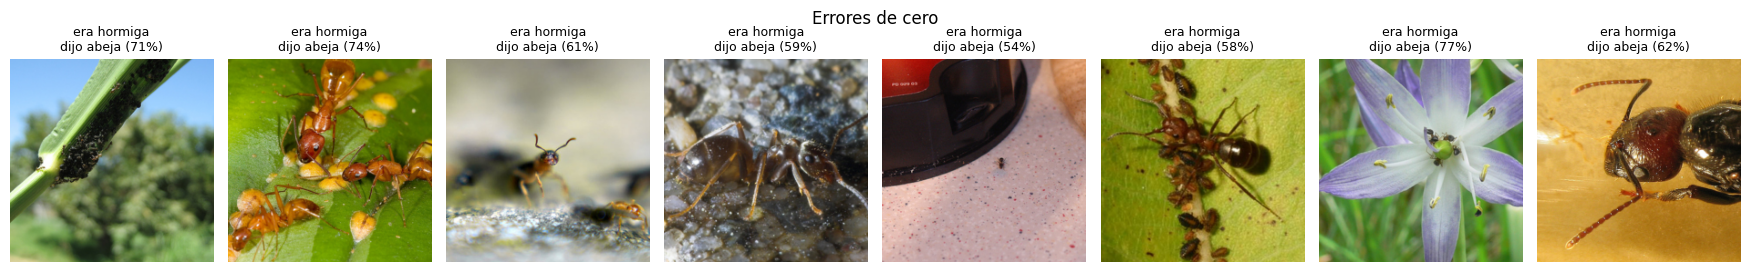

fe: 5 errores de 77 fotos


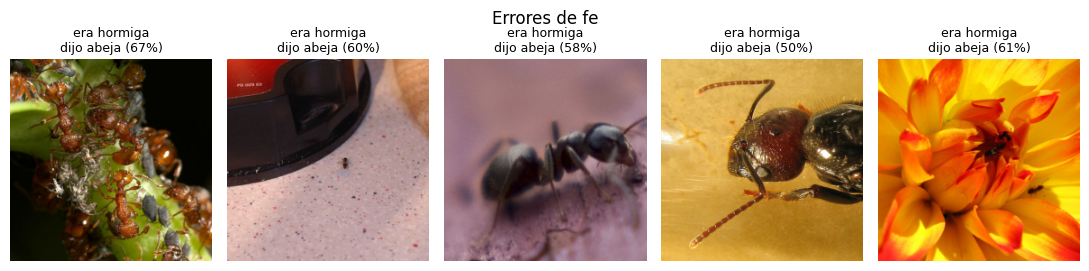

ft: 8 errores de 77 fotos


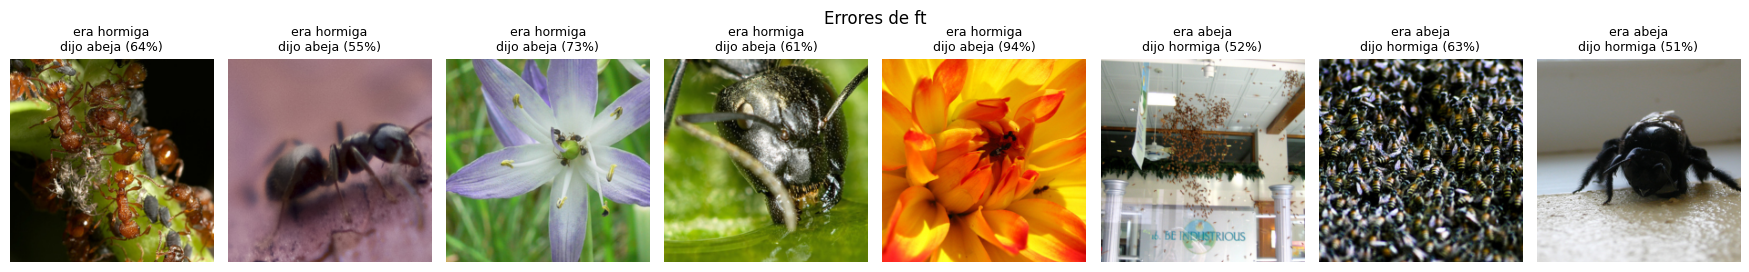

lr_alto: 9 errores de 77 fotos


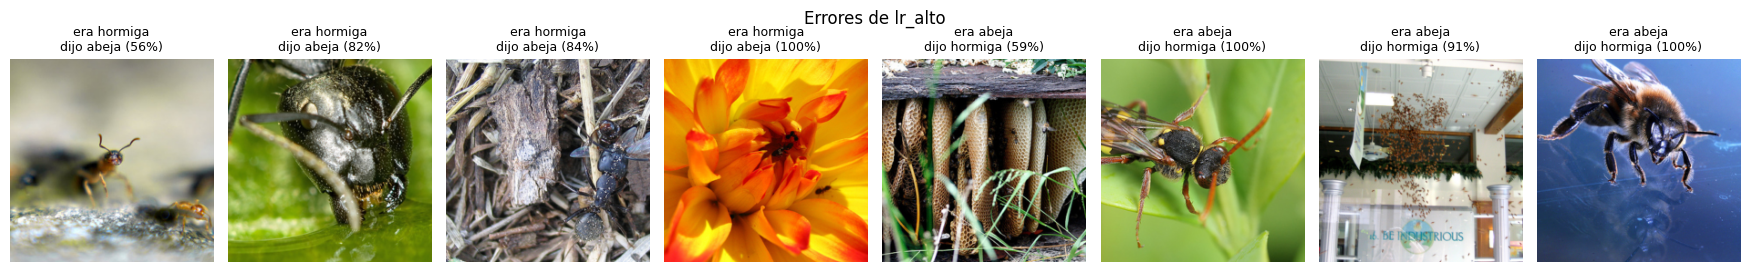

In [18]:
# Muestra hasta 'maximo' fotos de prueba mal clasificadas por un modelo
def ver_errores(nombre, maximo=8):
    # Probabilidades y etiquetas reales del modelo
    probs, ys = RES[nombre]["probs"], RES[nombre]["ys"]
    # Clase que dijo la red para cada foto
    pred = probs.argmax(1)
    # Posiciones de las fotos donde se equivocó
    malas = np.where(pred != ys)[0]
    # Avisamos cuántas son
    print(f"{nombre}: {len(malas)} errores de {len(ys)} fotos")
    # Si no hay errores, no dibujamos nada
    if len(malas) == 0:
        # Salimos de la función
        return
    # Nos quedamos con las primeras 'maximo'
    malas = malas[:maximo]
    # Una fila con un recuadro por foto mal clasificada
    fig, axes = plt.subplots(1, len(malas), figsize=(2.2 * len(malas), 2.8), squeeze=False)
    # Recorremos los recuadros y las fotos
    for ax, k in zip(axes[0], malas):
        # Ruta de la foto: k-ésima foto de prueba dentro de la carpeta val original
        ruta = ds_val_full.samples[idx_test[k]][0]
        # Mostramos la foto recortada al centro
        ax.imshow(abrir_centrada(ruta))
        # Título con lo que era, lo que dijo y con qué seguridad
        ax.set_title(f"era {CLASES[ys[k]]}\ndijo {CLASES[pred[k]]} ({probs[k, pred[k]]:.0%})", fontsize=9)
        # Sin ejes
        ax.axis("off")
    # Título del modelo
    plt.suptitle(f"Errores de {nombre}")
    # Ajuste de márgenes
    plt.tight_layout()
    # Mostramos
    plt.show()

# Recorremos los cuatro modelos
for n in ORDEN:
    # Mostramos sus errores
    ver_errores(n)

**Cómo leerlo.** Mira los errores de la red desde cero, muchos son hormigas grandes y claras, que cualquiera de nosotros reconoce, y eso dice que esa red todavía no aprendió a ver hormigas sino otras pistas de la foto, como el fondo o el color. Los errores de feature extraction son distintos, son fotos de verdad difíciles. En la corrida del docente, tres fotos las fallaron feature extraction y fine-tuning (y también el fine-tuning completo, que entrenó el docente y aquí no corremos), un montón de hormigas rojizas sobre un tallo, una hormiga muy borrosa y una flor amarilla enorme con una hormiga diminuta en una esquina, que la red tomó por abeja porque lo que domina la foto es una flor, justo el lugar donde suelen estar las abejas.

Mira también los errores de `lr_alto` y fíjate en los porcentajes, varios superan el 90 %. Ese es el modelo que se equivoca con aplomo.

---
## Parte 13 — TU TURNO

Tienes tres palancas. Mueve **una sola a la vez**, ejecuta su celda y compara con las cifras de la Parte 11. Antes de ejecutar, escribe en un comentario qué esperas que pase.

**Palanca 1.** Descongela también `layer3`. ¿Mejora o memoriza todavía más?

ft_layer3: 10,494,466 parámetros entrenables | mejor época 1 | validación 0.947 | prueba 0.896 | 28 s


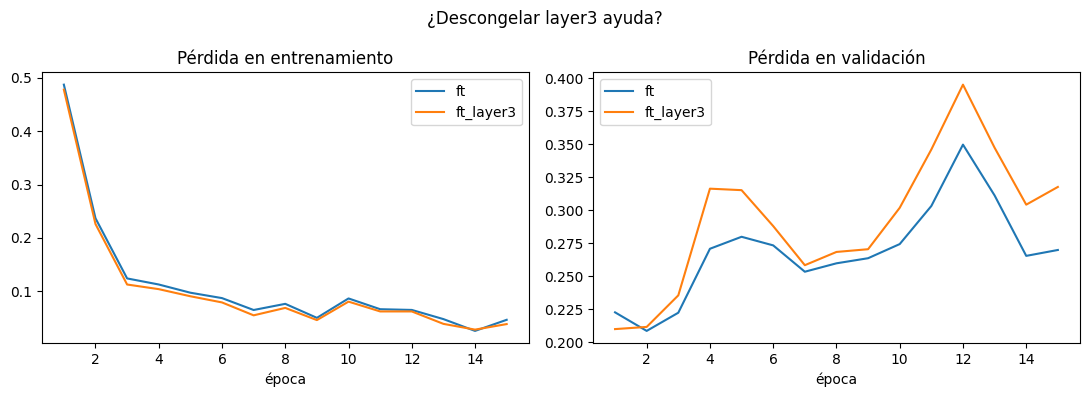

In [19]:
# Tu predicción (escríbela antes de ejecutar):
# Creo que no mejorará mucho y que la red memorizará más las fotos.
# Palanca 1: layer3, layer4 y cabeza activos, con la tasa del fine-tuning
run("ft_layer3", lambda: crear_resnet(True, "layer3"), ds_train, P["EP_TL"], P["LR_FT"], wd=P["WD"])
# Comparamos con el fine-tuning de la Parte 9 en pérdida, donde se ve la memorización
ver_curvas(["ft", "ft_layer3"], "¿Descongelar layer3 ayuda?", medida="loss")

**Palanca 2.** Cambia la tasa de aprendizaje del fine-tuning. Prueba `1e-3` (diez veces mayor) o `1e-5` (diez veces menor) en la variable `mi_lr`. ¿Cuál se parece más al enfermo de la Parte 10 y cuál aprende demasiado lento?

ft_lr_0.001: 8,394,754 parámetros entrenables | mejor época 9 | validación 0.947 | prueba 0.935 | 28 s


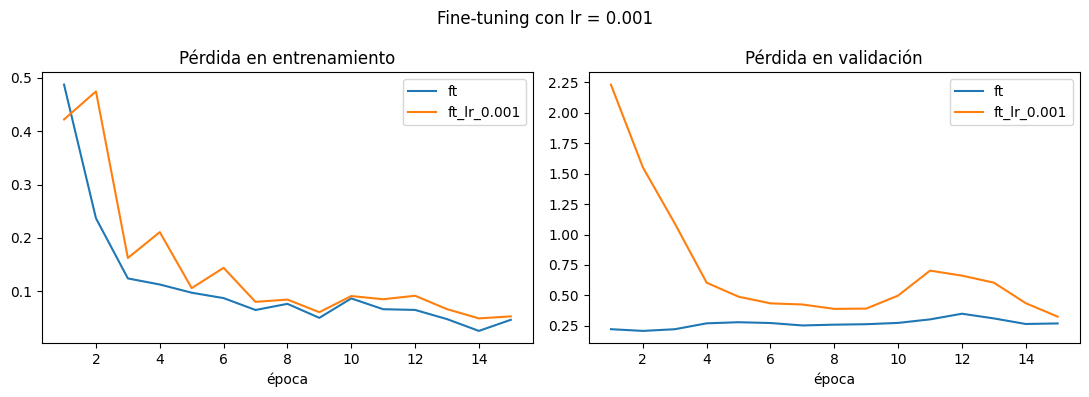

In [20]:
# Tu predicción (escríbela antes de ejecutar):
# Con 1e-3 se podria esperar resultados intermedios, con curvas más irregulares.
# Cambia este número por 1e-3 o por 1e-5
mi_lr = 1e-3
# El mismo fine-tuning de la Parte 9, con tu tasa de aprendizaje
run(f"ft_lr_{mi_lr}", lambda: crear_resnet(True, "layer4"), ds_train, P["EP_TL"], mi_lr, wd=P["WD"])
# Comparamos con el fine-tuning sano
ver_curvas(["ft", f"ft_lr_{mi_lr}"], f"Fine-tuning con lr = {mi_lr}", medida="loss")

**Palanca 3.** Quédate con solo **20 fotos por clase** (40 en total) y entrena las dos estrategias que más contrastan, desde cero y feature extraction. ¿Cuánto pierde cada una? En la corrida del docente, con 20 fotos por clase, la red desde cero quedó en 62,3 % y feature extraction en 84,4 %.

In [21]:
# Tu predicción (escríbela antes de ejecutar):
# Con solo 40 fotos, espero que la red entrenada desde cero tenga una precisión baja,
# cercana al azar, porque debe aprender demasiado con pocos datos.

# Fotos por clase que vamos a conservar
n_por_clase = 20
# Etiquetas de todas las fotos de entrenamiento
y_train = torch.tensor(ds_train.targets)
# Generador con semilla para elegir siempre las mismas fotos
g = torch.Generator().manual_seed(P["SEMILLA"])
# Aquí juntamos los índices elegidos
idx = []
# Clase por clase
for c in range(len(CLASES)):
    # Posiciones de las fotos de la clase c
    pos = torch.where(y_train == c)[0]
    # Las barajamos con la semilla
    pos = pos[torch.randperm(len(pos), generator=g)]
    # Tomamos las primeras n_por_clase
    idx += pos[:n_por_clase].tolist()
# Subconjunto de entrenamiento (conserva el aumento de datos)
ds_poco = torch.utils.data.Subset(ds_train, idx)
# Avisamos el tamaño
print("Fotos de entrenamiento:", len(ds_poco))

# Desde cero con pocas fotos
run("cero_poco", lambda: CNNDesdeCero(), ds_poco, P["EP_CERO"], P["LR_BASE"])
# Feature extraction con pocas fotos
run("fe_poco", lambda: crear_resnet(True, "cabeza"), ds_poco, P["EP_TL"], P["LR_BASE"])

Fotos de entrenamiento: 40
cero_poco: 389,890 parámetros entrenables | mejor época 21 | validación 0.697 | prueba 0.623 | 31 s
fe_poco: 1,026 parámetros entrenables | mejor época 15 | validación 0.816 | prueba 0.844 | 15 s


### Pregunta escrita del laboratorio (para entregar)

Con 244 fotos, congelar el cuerpo y entrenar solo 1 026 parámetros le ganó o empató a ajustar más de 8 millones con el fine-tuning. Explica en cinco o seis líneas **por qué**, usando lo que viste en las curvas de la Parte 9 y lo que aprendiste de sobreajuste en la Clase 7. Termina diciendo en qué situación de un proyecto real sí elegirías el fine-tuning.

In [24]:
# Escribe tu respuesta aquí, como comentario:
# Con solo 244 fotos, el fine-tuning tiene demasiados parámetros para tan pocos datos.
# Aunque llegó al 99 % de precisión en entrenamiento, empezó a fallar más en validación, señal de que estaba memorizando las fotos.
# En cambio, Feature Extraction aprovechó lo que la red ya sabía y obtuvo 93,5 %, frente al 89,6 % del fine-tuning.
# Aun así, con solo 77 fotos de prueba, la diferencia es pequeña.
# Usaría fine-tuning si tuviera miles de fotos o imágenes muy diferentes a las de ImageNet, como radiografías o imágenes satelitales.

---
## Cierre

Hoy dejamos de entrenar desde cero. Viste que una red preentrenada en ImageNet ya trae en su primera capa detectores de bordes y de color que nadie programó, y que ese saber se transfiere a un problema que ImageNet nunca le enseñó, distinguir abejas de hormigas. Con solo 1 026 parámetros entrenados, la estrategia de **feature extraction** pasó del 80,5 % de la red desde cero a 93,5 %, y el **fine-tuning** quedó prácticamente empatado, pero con señales claras de memorización, porque con pocas fotos dejar millones de parámetros libres invita a memorizar. También viste el error clásico, una tasa de aprendizaje alta que desordena en una época lo que ImageNet afinó, y deja un modelo que se equivoca muy seguro.

La regla para tu proyecto es sencilla. Empieza siempre por feature extraction, que es rápido, estable y difícil de arruinar, y pasa al fine-tuning solo si tienes bastantes más fotos y tu problema se aleja de las fotos de ImageNet.

**La próxima clase (Clase 9)** abrimos la caja que hoy usamos cerrada. ¿Por qué se puede entrenar una red de 18, 50 o 152 capas sin que se pierda en el camino? La respuesta son las **conexiones residuales**, la idea que le da su nombre a ResNet, y la veremos junto con otras arquitecturas modernas como VGG y EfficientNet.